# Global Superstore Sales & Profit Analytics

## Exploratory Data Analysis (EDA)

### 1. Introduction

Exploratory Data Analysis (EDA) is an important stage in data analytics that helps us understand patterns, trends, relationships, and unusual observations within a dataset.

In this phase, the cleaned Global Superstore dataset will be analyzed using Python to discover meaningful business insights related to sales performance, profitability, customer behavior, product performance, geographical performance, discounts, and shipping.

The findings from this analysis will help identify business opportunities, potential problems, and areas that require further investigation.

### 2. Objectives

The main objectives of this phase are:

- Understand the overall sales and profit performance.
- Analyze yearly and monthly sales and profit trends.
- Compare sales and profitability across product categories and subcategories.
- Identify top-performing and loss-making products.
- Analyze customer segments and identify valuable customers.
- Compare business performance across markets and regions.
- Investigate the relationship between discounts and profitability.
- Analyze shipping modes and shipping duration.
- Create visualizations to communicate important findings.
- Prepare key insights for SQL analysis and Power BI dashboard development.

### 3. Tools and Libraries

The following tools and libraries will be used:

- **Python:** Data analysis and calculations.
- **Pandas:** Data manipulation, grouping, aggregation, and summarization.
- **NumPy:** Numerical calculations.
- **Matplotlib:** Data visualization.
- **Seaborn:** Statistical visualizations and relationship analysis.
- **Jupyter Notebook:** Interactive analysis and documentation.

### 4. EDA Workflow

The analysis will follow these steps:

1. Load the cleaned dataset.
2. Inspect the dataset structure and verify data types.
3. Calculate key performance indicators (KPIs).
4. Analyze yearly and monthly sales and profit trends.
5. Explore category and subcategory performance.
6. Analyze customer segments and top customers.
7. Compare sales and profitability across markets and regions.
8. Investigate discount levels and their relationship with profit.
9. Analyze shipping modes and shipping duration.
10. Create and save relevant charts.
11. Summarize the key business findings.

### 5. Key Performance Indicators (KPIs)

The following metrics will be calculated:

- **Total Sales:** Overall revenue generated from sales.
- **Total Profit:** Overall profit or loss recorded.
- **Total Quantity Sold:** Total quantity of products sold.
- **Total Orders:** Number of distinct orders.
- **Total Customers:** Number of distinct customers.
- **Profit Margin:** Total profit divided by total sales.
- **Average Order Value (AOV):** Total sales divided by the number of distinct orders.

### 6. Expected Outcome

At the end of this phase, the project will contain meaningful business insights, summary tables, and visualizations that explain the performance of the Global Superstore business.

The findings will support **SQL Business Analysis** and **Power BI Dashboard Development**.

**Note:** All conclusions will be based on the actual results obtained from the cleaned dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

# Output folder for charts
Path("../images").mkdir(parents=True, exist_ok=True)

# Load cleaned dataset
df = pd.read_csv("../data/processed/superstore_cleaned.csv")

# Convert date columns
df["Order_Date"] = pd.to_datetime(df["Order_Date"])
df["Ship_Date"] = pd.to_datetime(df["Ship_Date"])

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (51290, 32)


,Category,City,Country,Customer_ID,Customer_Name,Discount,Market,Record_Count,Order_Date,Order_ID,...,State,Sub_Category,Year,Market2,Weeknum,Order_Year,Order_Month,Month_Name,Year_Month,Shipping_Days
0,Office Supplies,Los Angeles,United States,LS-172304,Lycoris Saunders,0.0,US,1,2011-01-07,CA-2011-130813,...,California,Paper,2011,North America,2,2011,1,January,2011-01,2
1,Office Supplies,Los Angeles,United States,MV-174854,Mark Van Huff,0.0,US,1,2011-01-21,CA-2011-148614,...,California,Paper,2011,North America,4,2011,1,January,2011-01,5
2,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-05,CA-2011-118962,...,California,Paper,2011,North America,32,2011,8,August,2011-08,4
3,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-05,CA-2011-118962,...,California,Paper,2011,North America,32,2011,8,August,2011-08,4
4,Office Supplies,Los Angeles,United States,AP-109154,Arthur Prichep,0.0,US,1,2011-09-29,CA-2011-146969,...,California,Paper,2011,North America,40,2011,9,September,2011-09,4


In [2]:
# Overall business performance

total_sales = df["Sales"].sum()

total_profit = df["Profit"].sum()

total_quantity = df["Quantity"].sum()

total_orders = df["Order_ID"].nunique()

total_customers = df["Customer_ID"].nunique()

profit_margin = (total_profit / total_sales * 100 if total_sales != 0 else np.nan)

kpis = pd.DataFrame({
    "Metric": [
        "Total Sales",
        "Total Profit",
        "Total Quantity",
        "Total Orders",
        "Total Customers",
        "Profit Margin (%)"
    ],
    "Value": [
        total_sales,
        total_profit,
        total_quantity,
        total_orders,
        total_customers,
        profit_margin
    ]
})

kpis

              Metric         Value
0        Total Sales  1.264290e+07
1       Total Profit  1.467457e+06
2     Total Quantity  1.783120e+05
3       Total Orders  2.503500e+04
4    Total Customers  4.873000e+03
5  Profit Margin (%)  1.160696e+01

In [3]:
df["Order_Year"] = df["Order_Date"].dt.year

yearly_performance = (
    df.groupby("Order_Year")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Total_Orders=("Order_ID", "nunique")
      )
      .reset_index()
)

yearly_performance["Profit_Margin"] = (
    yearly_performance["Total_Profit"]
    / yearly_performance["Total_Sales"] * 100
)

yearly_performance

   Order_Year  Total_Sales  Total_Profit  Total_Orders  Profit_Margin
0        2011      2259511  248940.81154          4440      11.017464
1        2012      2677493  307415.27910          5343      11.481460
2        2013      3405860  406935.23018          6721      11.948090
3        2014      4300041  504165.97046          8531      11.724678

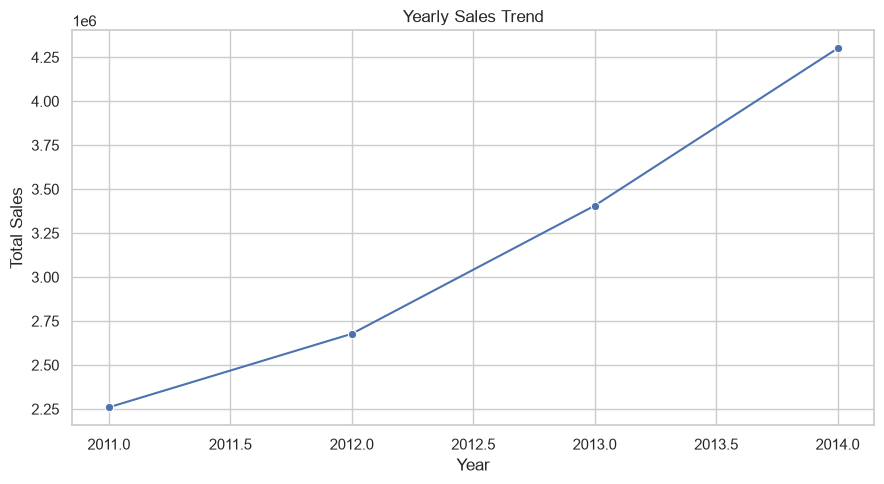

In [4]:
# Visualize yearly sales

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=yearly_performance,
    x="Order_Year",
    y="Total_Sales",
    marker="o"
)

plt.title("Yearly Sales Trend")
plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.tight_layout()

plt.savefig("../images/yearly_sales.png", dpi=150)
plt.show()

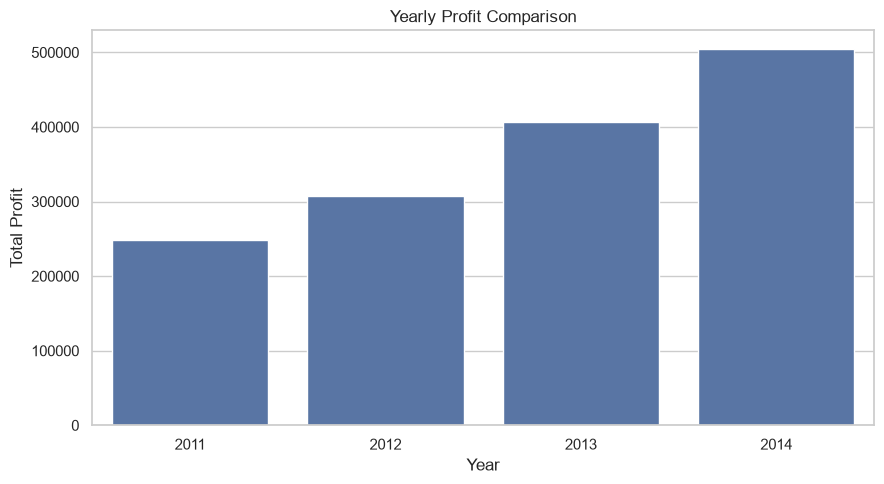

In [5]:
# Visualize yearly profit

plt.figure(figsize=(9, 5))

sns.barplot(
    data=yearly_performance,
    x="Order_Year",
    y="Total_Profit"
)

plt.title("Yearly Profit Comparison")
plt.xlabel("Year")
plt.ylabel("Total Profit")
plt.tight_layout()

plt.savefig("../images/yearly_profit.png", dpi=150)
plt.show()

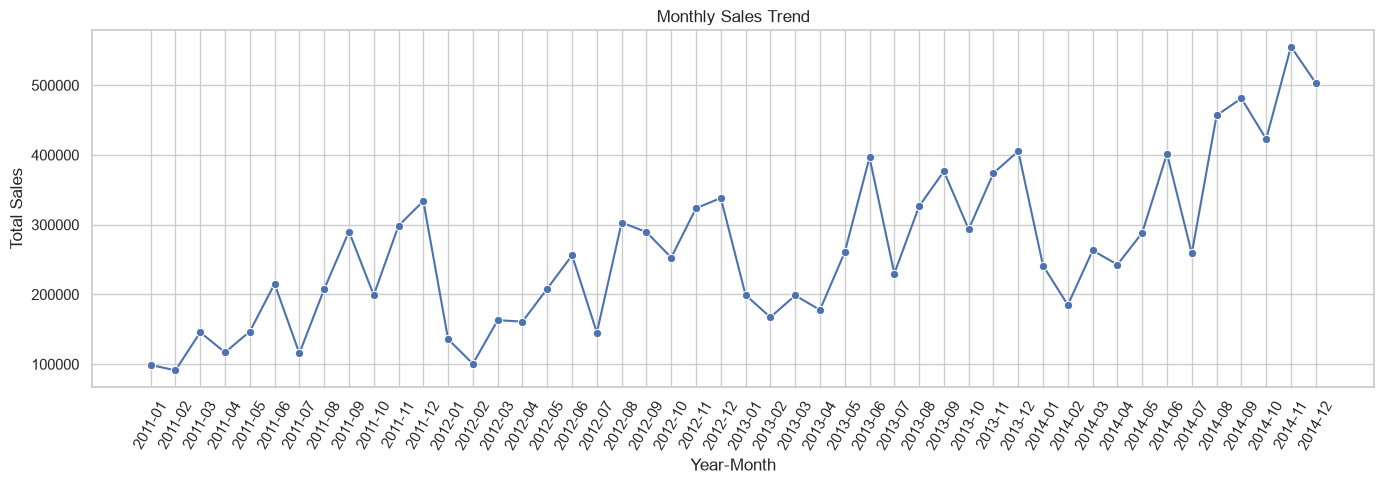

   Year_Month  Total_Sales  Total_Profit
46    2014-11       555312   62856.58790
47    2014-12       503154   46916.52068
44    2014-09       481186   67979.45110
43    2014-08       456633   53542.89496
45    2014-10       422785   58209.83476

In [6]:
# Monthly sales trends

# Which months perform best, and are there recurring seasonal patterns?

df["Year_Month"] = (
    df["Order_Date"].dt.to_period("M").astype(str)
)

monthly_sales = (
    df.groupby("Year_Month")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum")
      )
      .reset_index()
      .sort_values("Year_Month")
)

plt.figure(figsize=(14, 5))

sns.lineplot(
    data=monthly_sales,
    x="Year_Month",
    y="Total_Sales",
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Year-Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=60)
plt.tight_layout()

plt.savefig("../images/monthly_sales.png", dpi=150)
plt.show()

# Identify the top five sales months

top_5_months = monthly_sales.nlargest(5, "Total_Sales")

top_5_months

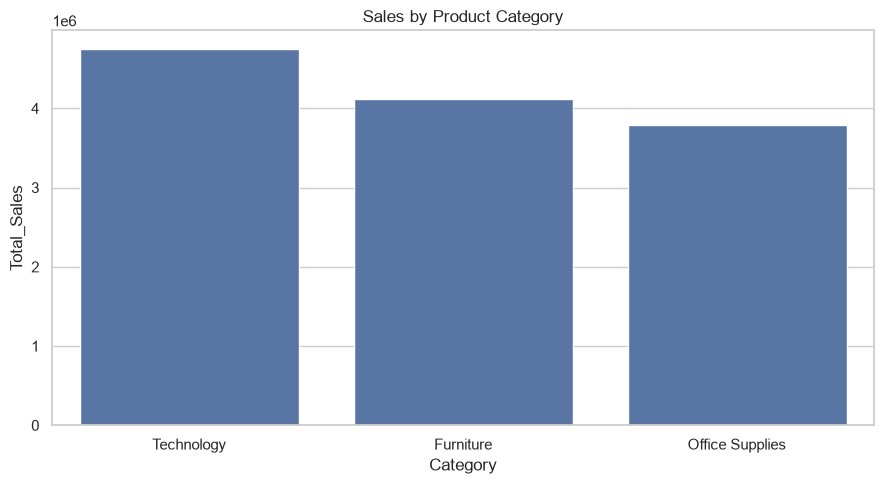

           Category Sub_Category  Total_Sales  Total_Profit
3         Furniture       Tables       757034   -64083.3887
8   Office Supplies    Fasteners        83254    11525.4241
9   Office Supplies       Labels        73433    15010.5120
12  Office Supplies     Supplies       243090    22583.2631
7   Office Supplies    Envelopes       170926    29601.1163

In [7]:
# Category and sub-category analysis

# Which category generates the most sales?

# Which category generates the most profit?

# Which sub-categories are loss-making?

category_analysis = (
    df.groupby("Category")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Quantity_Sold=("Quantity", "sum")
      )
      .reset_index()
)

category_analysis["Profit_Margin"] = (
    category_analysis["Total_Profit"]
    / category_analysis["Total_Sales"] * 100
)

category_analysis.sort_values("Total_Sales", ascending=False)

# Sales by category

plt.figure(figsize=(9, 5))

sns.barplot(
    data=category_analysis.sort_values(
        "Total_Sales", ascending=False
    ),
    x="Category",
    y="Total_Sales"
)

plt.title("Sales by Product Category")
plt.tight_layout()

plt.savefig("../images/category_sales.png", dpi=150)
plt.show()

# Investigate sub-categories

subcategory_analysis = (
    df.groupby(["Category", "Sub_Category"])
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum")
      )
      .reset_index()
      .sort_values("Total_Profit")
)

subcategory_analysis

# The five lowest-profit sub-categories

subcategory_analysis.head(5)

In [8]:
# Product profitability

# Which products generate the highest sales?

product_analysis = (
    df.groupby(["Product_ID", "Product_Name"])
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Quantity_Sold=("Quantity", "sum")
      )
      .reset_index()
)

top_products = product_analysis.nlargest(10, "Total_Sales")

top_products


            Product_ID                                       Product_Name  \
9388   TEC-CO-10004722              Canon imageCLASS 2200 Advanced Copier   
10632  TEC-PH-10004664                  Nokia Smart Phone, with Caller ID   
4017   OFF-BI-10003527  Fellowes PB500 Electric Punch Plastic Comb Bin...   
9721   TEC-MA-10002412  Cisco TelePresence System EX90 Videoconferenci...   
10646  TEC-PH-10004823                       Nokia Smart Phone, Full Size   
745    FUR-CH-10002024       HON 5400 Series Task Chairs for Big and Tall   
541    FUR-CH-10000027            SAFCO Executive Leather Armchair, Black   
2882   OFF-AP-10004512                                  Hoover Stove, Red   
3744   OFF-BI-10001359         GBC DocuBind TL300 Electric Binding System   
3634   OFF-BI-10000545   GBC Ibimaster 500 Manual ProClick Binding System   

       Total_Sales  Total_Profit  Quantity_Sold  
9388         61600  2.519993e+04             20  
10632        30042  5.455948e+03             52  
40

In [9]:
# Product profitability

# Which products generate the lowest profit?

bottom_products = product_analysis.nsmallest(10, "Total_Profit")

bottom_products

             Product_ID                                       Product_Name  \
9574    TEC-MA-10000418          Cubify CubeX 3D Printer Double Head Print   
2614    OFF-AP-10001623                                Hoover Stove, White   
9605    TEC-MA-10000822          Lexmark MX611dhe Monochrome Laser Printer   
10424   TEC-PH-10002991                       Apple Smart Phone, Full Size   
9984   TEC-MOT-10003050                     Motorola Smart Phone, Cordless   
9876    TEC-MA-10004125          Cubify CubeX 3D Printer Triple Head Print   
699     FUR-CH-10001582      Office Star Executive Leather Armchair, Black   
1993    FUR-TA-10000198  Chromcraft Bull-Nose Wood Oval Conference Tabl...   
2157    FUR-TA-10002885              Lesro Computer Table, Fully Assembled   
2118    FUR-TA-10002172                  Hon Conference Table, Rectangular   

       Total_Sales  Total_Profit  Quantity_Sold  
9574         11100    -8879.9704              9  
2614         11730    -4958.1630         

In [10]:
# Product profitability

# Which products have high sales but negative profit?

high_sales_loss_products = product_analysis[
    (product_analysis["Total_Sales"] > 0)
    & (product_analysis["Total_Profit"] < 0)
].sort_values("Total_Sales", ascending=False)

high_sales_loss_products.head(10)

            Product_ID                                       Product_Name  \
9721   TEC-MA-10002412  Cisco TelePresence System EX90 Videoconferenci...   
4214   OFF-BI-10004995          GBC DocuBind P400 Electric Binding System   
233    FUR-BO-10001934                     Bush Library with Doors, Metal   
7770   OFF-SU-10000151        High Speed Automatic Electric Letter Opener   
9605   TEC-MA-10000822          Lexmark MX611dhe Monochrome Laser Printer   
771    FUR-CH-10002213              Hon Executive Leather Armchair, Black   
8013   OFF-SU-10002881  Martin Yale Chadless Opener Electric Letter Op...   
10568  TEC-PH-10004196                      Samsung Smart Phone, Cordless   
497    FUR-BO-10004834  Riverside Palais Royal Lawyers Bookcase, Royal...   
595    FUR-CH-10000602            Novimex Executive Leather Armchair, Red   

       Total_Sales  Total_Profit  Quantity_Sold  
9721         22638    -1811.0784              6  
4214         17965    -1878.1662             27  
23

In [11]:
# Customer and segment analysis

# Which customer segments contribute most to sales and profit?

segment_analysis = (
    df.groupby("Segment")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Total_Orders=("Order_ID", "nunique"),
          Total_Customers=("Customer_ID", "nunique")
      )
      .reset_index()
)

segment_analysis

# Top 10 customers by sales

customer_analysis = (
    df.groupby(["Customer_ID", "Customer_Name"])
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Total_Orders=("Order_ID", "nunique")
      )
      .reset_index()
)

customer_analysis.nlargest(10, "Total_Sales")

     Customer_ID  Customer_Name  Total_Sales  Total_Profit  Total_Orders
4306   SM-203204    Sean Miller        25042    -1980.7393             5
4564   TC-209804   Tamara Chand        19050     8981.3239             5
1042   CS-118451     Cari Sayre        16655     2995.5816            11
4359   SP-209202   Susan Pistek        16566     4974.5130            12
4792   VG-218051    Vivek Grady        15654     2748.1878             7
3816   RB-193604   Raymond Buch        15117     6976.0959             6
3611   PF-191201   Peter Fuller        15063      968.2725             8
4487   TA-213854   Tom Ashbrook        14596     4703.7883             4
490    BF-110051    Barry Franz        14563     2272.4889             9
37     AB-101054  Adrian Barton        14476     5444.8055            10

In [12]:
# Top 10 customers by sales

customer_analysis = (
    df.groupby(["Customer_ID", "Customer_Name"])
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Total_Orders=("Order_ID", "nunique")
      )
      .reset_index()
)

customer_analysis.nlargest(10, "Total_Sales")

     Customer_ID  Customer_Name  Total_Sales  Total_Profit  Total_Orders
4306   SM-203204    Sean Miller        25042    -1980.7393             5
4564   TC-209804   Tamara Chand        19050     8981.3239             5
1042   CS-118451     Cari Sayre        16655     2995.5816            11
4359   SP-209202   Susan Pistek        16566     4974.5130            12
4792   VG-218051    Vivek Grady        15654     2748.1878             7
3816   RB-193604   Raymond Buch        15117     6976.0959             6
3611   PF-191201   Peter Fuller        15063      968.2725             8
4487   TA-213854   Tom Ashbrook        14596     4703.7883             4
490    BF-110051    Barry Franz        14563     2272.4889             9
37     AB-101054  Adrian Barton        14476     5444.8055            10

In [13]:
# Geographic analysis

market_analysis = (
    df.groupby("Market")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Total_Orders=("Order_ID", "nunique")
      )
      .reset_index()
      .sort_values("Total_Sales", ascending=False)
)

market_analysis

   Market  Total_Sales  Total_Profit  Total_Orders
0    APAC      3585833  436000.04900          5437
4      EU      2938139  372829.74150          4593
6      US      2297354  286397.02170          5009
5   LATAM      2164687  221643.48708          5138
3    EMEA       806184   43897.97100          2462
1  Africa       783776   88871.63100          2232
2  Canada        66932   17817.39000           201

In [14]:
# Analyze regions

region_analysis = (
    df.groupby("Region")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum")
      )
      .reset_index()
      .sort_values("Total_Profit")
)

region_analysis

            Region  Total_Sales  Total_Profit
1           Canada        66932   17817.39000
11  Southeast Asia       884438   17852.32900
2        Caribbean       324281   34571.32104
5             EMEA       806184   43897.97100
0           Africa       783776   88871.63100
6             East       678834   91522.78000
12            West       725514  108418.44890
9          Oceania      1100207  120089.11200
4     Central Asia       752839  132480.18700
10           South      1600960  140355.76618
8       North Asia       848349  165578.42100
7            North      1248192  194597.95252
3          Central      2822399  311403.98164

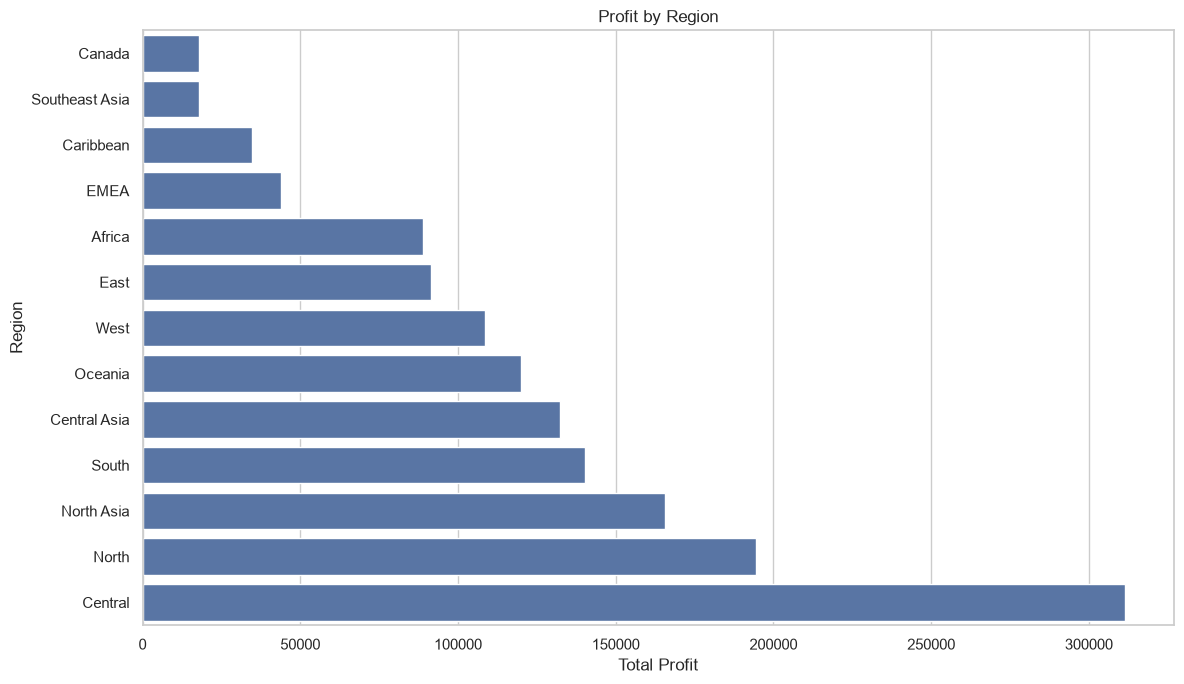

In [15]:
# Visualize regional profit

plt.figure(figsize=(12, 7))

sns.barplot(
    data=region_analysis,
    x="Total_Profit",
    y="Region"
)

plt.title("Profit by Region")
plt.xlabel("Total Profit")
plt.ylabel("Region")
plt.tight_layout()

plt.savefig("../images/region_profit.png", dpi=150)
plt.show()

In [16]:
# Discount versus profit

# Inspect the discount distribution

print(df["Discount"].describe())
print("Unique discount values:", sorted(df["Discount"].dropna().unique()))

count    51290.000000
mean         0.142908
std          0.212280
min          0.000000
25%          0.000000
50%          0.000000
75%          0.200000
max          0.850000
Name: Discount, dtype: float64
Unique discount values: [np.float64(0.0), np.float64(0.002), np.float64(0.07), np.float64(0.1), np.float64(0.15), np.float64(0.17), np.float64(0.2), np.float64(0.202), np.float64(0.25), np.float64(0.27), np.float64(0.3), np.float64(0.32), np.float64(0.35), np.float64(0.37), np.float64(0.4), np.float64(0.402), np.float64(0.45), np.float64(0.47), np.float64(0.5), np.float64(0.55), np.float64(0.57), np.float64(0.6), np.float64(0.602), np.float64(0.65), np.float64(0.7), np.float64(0.8), np.float64(0.85)]


In [17]:
# Create discount groups

df["Discount_Band"] = pd.cut(
    df["Discount"],
    bins=[-0.001, 0, 0.10, 0.20, 0.30, 0.50, 1.00],
    labels=[
        "No Discount",
        "0–10%",
        "10–20%",
        "20–30%",
        "30–50%",
        "50–100%"
    ],
    include_lowest=True
)

discount_analysis = (
    df.groupby("Discount_Band", observed=True)
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Records=("Row_ID", "count")
      )
      .reset_index()
)

discount_analysis["Profit_Margin"] = (
    discount_analysis["Total_Profit"]
    / discount_analysis["Total_Sales"] * 100
)

discount_analysis

  Discount_Band  Total_Sales  Total_Profit  Records  Profit_Margin
0   No Discount      6992734  1.770695e+06    29009      25.321931
1         0–10%      1962633  3.381893e+05     4679      17.231406
2        10–20%      1757296  1.732548e+05     6274       9.859172
3        20–30%       382540 -2.115561e+04      967      -5.530301
4        30–50%      1176078 -3.809448e+05     6189     -32.391118
5       50–100%       371624 -4.125817e+05     4172    -111.021263

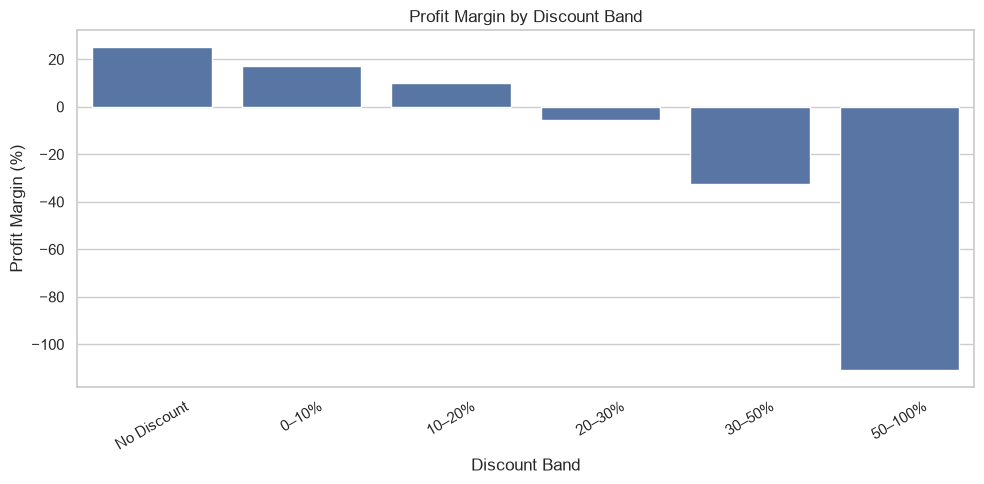

In [18]:
# Visualize the relationship

plt.figure(figsize=(10, 5))

sns.barplot(
    data=discount_analysis,
    x="Discount_Band",
    y="Profit_Margin"
)

plt.title("Profit Margin by Discount Band")
plt.xlabel("Discount Band")
plt.ylabel("Profit Margin (%)")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig("../images/discount_profit_margin.png", dpi=150)
plt.show()

In [19]:
# Shipping analysis

shipping_analysis = (
    df.groupby("Ship_Mode")
      .agg(
          Total_Orders=("Order_ID", "nunique"),
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Total_Shipping_Cost=("Shipping_Cost", "sum"),
          Average_Shipping_Days=("Shipping_Days", "mean")
      )
      .reset_index()
)

shipping_analysis

        Ship_Mode  Total_Orders  Total_Sales  Total_Profit  \
0     First Class          3821      1831067  208104.67520   
1        Same Day          1347       667202   76173.06780   
2    Second Class          5119      2565747  292583.52708   
3  Standard Class         15154      7578889  890596.02120   

   Total_Shipping_Cost  Average_Shipping_Days  
0         308102.54154               2.181746  
1         115973.71600               0.037394  
2         314111.79036               3.230187  
3         614627.65550               4.998018  

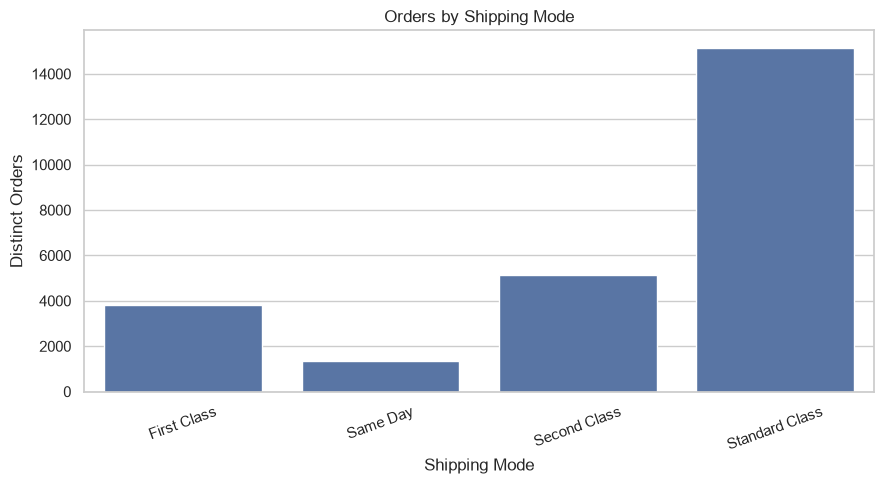

In [20]:
# Visualize the number of distinct orders

plt.figure(figsize=(9, 5))

sns.barplot(
    data=shipping_analysis,
    x="Ship_Mode",
    y="Total_Orders"
)

plt.title("Orders by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Distinct Orders")
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig("../images/shipping_mode.png", dpi=150)
plt.show()

In [21]:
# Save your analysis outputs

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

yearly_performance.to_csv(
    output_dir / "yearly_performance.csv", index=False
)

category_analysis.to_csv(
    output_dir / "category_analysis.csv", index=False
)

subcategory_analysis.to_csv(
    output_dir / "subcategory_analysis.csv", index=False
)

market_analysis.to_csv(
    output_dir / "market_analysis.csv", index=False
)

discount_analysis.to_csv(
    output_dir / "discount_analysis.csv", index=False
)

shipping_analysis.to_csv(
    output_dir / "shipping_analysis.csv", index=False
)

print("EDA summary tables saved successfully.")

EDA summary tables saved successfully.


## Conclusion: Exploratory Data Analysis (EDA)

### 1. Summary

In this phase, the cleaned Global Superstore dataset was explored using Python and data visualization techniques. The analysis focused on understanding business performance, identifying trends, comparing product and customer segments, and investigating factors associated with profitability.

### 2. Tasks Completed

- [ ] Loaded the cleaned dataset successfully.
- [ ] Verified the dataset structure and data types.
- [ ] Calculated overall business KPIs.
- [ ] Analyzed yearly and monthly sales and profit trends.
- [ ] Compared sales and profit across categories and subcategories.
- [ ] Identified top-performing and loss-making products.
- [ ] Analyzed customer segments and top customers.
- [ ] Compared performance across markets and regions.
- [ ] Investigated discounts and their relationship with profitability.
- [ ] Analyzed shipping modes and shipping duration.
- [ ] Created and reviewed relevant charts.
- [ ] Recorded key business insights.
- [ ] Saved important charts and summary tables where required.

### 3. Key Business Insights

Complete this section using the actual results from your analysis.

- **Overall Performance:** Summarize total sales, total profit, and profit margin.
- **Sales Trends:** Identify the strongest and weakest periods by sales.
- **Product Performance:** Identify the best-performing and loss-making categories or subcategories.
- **Customer Insights:** Describe the most valuable customer segments or customers.
- **Regional Performance:** Identify the strongest and weakest markets or regions.
- **Discount Analysis:** Explain any observed relationship between discounts and profitability.
- **Shipping Analysis:** Summarize differences in shipping performance.
- **Business Recommendations:** Suggest practical actions supported by the findings.

### 4. Output Files

Record the files created during this phase:

- **Notebook:** `notebooks/03_exploratory_data_analysis.ipynb`
- **Charts:** `images/`
- **Summary tables:** `data/processed/` (if exported)

### 5. Key Findings and Limitations

The results of this analysis describe patterns and relationships in the available dataset. An observed relationship, such as higher discounts occurring alongside lower profits, does not by itself prove that one factor caused the other.

Document any data limitations, unusual observations, or additional analysis that may be required.

### 6. Next Phase

The next phase is **SQL Business Analysis**.

In the SQL phase, the business questions explored using Python will be investigated using MySQL. SQL queries will be developed to analyze sales trends, customer performance, product profitability, regional performance, and discount patterns.

### Final Outcome

This phase establishes a clear understanding of Global Superstore's sales and profitability patterns and prepares the project for SQL analysis and interactive Power BI dashboard development.